# Support Vector Regression: predicting the output of a power plant

**Goal.** Fit a function that ignores small errors.

**The idea.** SVR places a tube of half-width $\varepsilon$ around the function. Points inside the tube cost nothing:

$$L_\varepsilon(y, \hat y) = \max(0, |y - \hat y| - \varepsilon)$$

Only points on or outside the tube become **support vectors**. A kernel lets the function be curved.

**The dataset.** *Combined Cycle Power Plant* (UCI): 9,568 hourly records. Inputs: ambient temperature `AT`, exhaust vacuum `V`,
ambient pressure `AP`, humidity `RH`. Target: electrical output `PE` in MW.
The split is the same as in `01_linear_regression.ipynb`, so all regression notebooks on this data can be compared directly.

In [1]:
# SETUP: install any package this notebook needs but your Python does not have.
# It uses the same Python that runs this notebook, so it also works on Windows
# inside a virtual environment or Anaconda.
import importlib.util
import subprocess
import sys

required = {  # import name -> pip package name
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",
    "certifi": "certifi",
    "openpyxl": "openpyxl"
}
missing = [pip for module, pip in required.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("All required packages are already installed.")

All required packages are already installed.


In [2]:
# A consistent look for every figure, and a fixed random seed so that
# running the notebook twice gives the same numbers.
import warnings
import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

PURPLE, BLUE, GREEN, ORANGE, RED = "#5A28C8", "#476ADD", "#00A651", "#F28C28", "#E0344B"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 12, "axes.titleweight": "bold", "axes.titlecolor": PURPLE,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

## 1. Get the data

In [3]:
# DOWNLOAD THE DATASET
# Files are stored next to this notebook in a "data" folder, and are only
# downloaded the first time. pathlib builds correct paths on Windows.
#
# Why certifi? Some Windows machines have an out-of-date certificate store and
# fail with CERTIFICATE_VERIFY_FAILED. certifi ships an up-to-date list of trusted
# authorities, so the secure connection is still fully verified.
import shutil
import ssl
import urllib.request
import zipfile
from pathlib import Path

import certifi

def download(url, destination):
    """Download url to destination unless the file already exists."""
    destination = Path(destination)
    if destination.exists():
        print("Already downloaded:", destination)
        return destination
    destination.parent.mkdir(parents=True, exist_ok=True)
    print("Downloading:", url)
    context = ssl.create_default_context(cafile=certifi.where())
    request = urllib.request.Request(url, headers={"User-Agent": "python"})
    temporary = destination.with_suffix(destination.suffix + ".part")
    with urllib.request.urlopen(request, context=context, timeout=600) as response, open(temporary, "wb") as output:
        shutil.copyfileobj(response, output)
    temporary.replace(destination)  # only a complete file gets the final name
    print("Saved:", destination, f"({destination.stat().st_size / 1e6:.1f} MB)")
    return destination

DATA_DIR = Path("data") / "ccpp"
archive = download("https://archive.ics.uci.edu/static/public/294/combined+cycle+power+plant.zip", DATA_DIR / "dataset.zip")
with zipfile.ZipFile(archive) as z:
    z.extractall(DATA_DIR)
print("Files:", [p.name for p in DATA_DIR.rglob("*") if p.is_file()][:10])

Already downloaded: data\ccpp\dataset.zip
Files: ['dataset.zip', 'Folds5x2_pp.ods', 'Folds5x2_pp.xlsx', 'Readme.txt', 'Readme.txt~']


In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_excel(DATA_DIR / "CCPP" / "Folds5x2_pp.xlsx", sheet_name=0)
X = df[["AT", "V", "AP", "RH"]]
y = df["PE"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (7654, 4) Test: (1914, 4)


## 2. Tune and train
Grid search on a random sample keeps tuning fast. The best settings are then used on the whole training set. Both inputs and target are scaled.

In [5]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

def build(C=1.0, gamma=1.0):
    return TransformedTargetRegressor(regressor=make_pipeline(StandardScaler(), SVR(C=C, gamma=gamma, epsilon=0.1)),
                                      transformer=StandardScaler())

C_values, gamma_values = [1, 10, 100, 1000], [0.01, 0.05, 0.1, 0.5, 1]
sample = X_train.sample(2500, random_state=SEED)
search = GridSearchCV(build(), {"regressor__svr__C": C_values, "regressor__svr__gamma": gamma_values},
                      cv=3, scoring="neg_root_mean_squared_error", n_jobs=-1).fit(sample, y_train.loc[sample.index])
heatmap = -search.cv_results_["mean_test_score"].reshape(len(C_values), len(gamma_values))
best_C, best_gamma = search.best_params_["regressor__svr__C"], search.best_params_["regressor__svr__gamma"]
print("Best C:", best_C, "| Best gamma:", best_gamma)

model = build(best_C, best_gamma).fit(X_train, y_train)
n_support = int(model.regressor_.named_steps["svr"].support_.size)
print("Support vectors:", n_support, "of", len(X_train))

Best C: 10 | Best gamma: 0.05


Support vectors: 5112 of 7654


## 3. Evaluate on the test set

In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred = model.predict(X_test)
rmse = float(np.sqrt(mean_squared_error(y_test, y_pred)))
mae = float(mean_absolute_error(y_test, y_pred))
r2 = float(r2_score(y_test, y_pred))

# The plain linear model is the reference every other regressor has to beat.
linear_rmse = float(np.sqrt(mean_squared_error(y_test, LinearRegression().fit(X_train, y_train).predict(X_test))))
print(f"RMSE = {rmse:.2f} MW | MAE = {mae:.2f} MW | R2 = {r2:.4f}")
print(f"Linear regression RMSE for reference: {linear_rmse:.2f} MW")

RMSE = 4.09 MW | MAE = 3.16 MW | R2 = 0.9424
Linear regression RMSE for reference: 4.50 MW


## 4. Look at the results

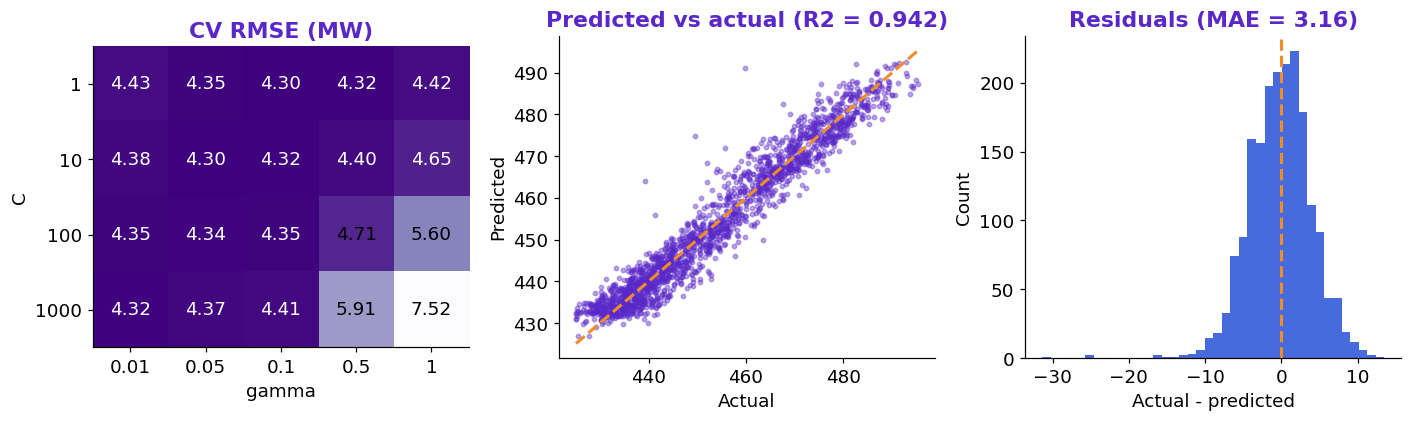

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4))

ax[0].imshow(heatmap, cmap="Purples_r")
for (i, j), v in np.ndenumerate(heatmap):
    ax[0].text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v < heatmap.mean() else "black")
ax[0].set(title="CV RMSE (MW)", xticks=range(5), yticks=range(4), xticklabels=gamma_values, yticklabels=C_values, xlabel="gamma", ylabel="C")

ax[1].scatter(y_test, y_pred, s=8, alpha=0.4, color=PURPLE)
limits = [y_test.min(), y_test.max()]
ax[1].plot(limits, limits, "--", color=ORANGE, lw=2)
ax[1].set(title=f"Predicted vs actual (R2 = {r2:.3f})", xlabel="Actual", ylabel="Predicted")

ax[2].hist(y_test - y_pred, bins=40, color=BLUE)
ax[2].axvline(0, color=ORANGE, lw=2, ls="--")
ax[2].set(title=f"Residuals (MAE = {mae:.2f})", xlabel="Actual - predicted", ylabel="Count")
fig.tight_layout()
plt.show()

In [8]:
# SAVE THE RESULTS. The figure and the metrics are written to a "results" folder.
# These exact files are what the course slides show.
import json

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)
fig.savefig(results_dir / "16_svr.png", dpi=170, bbox_inches="tight", facecolor="white")

results = {
    "model": "Support Vector Regression",
    "dataset": "Combined Cycle Power Plant (UCI)",
    "n_samples": int(len(df)),
    "metrics": {"RMSE (MW)": round(rmse, 2), "MAE (MW)": round(mae, 2), "R2": round(r2, 4), "Linear RMSE (MW)": round(linear_rmse, 2), "Best C": best_C, "Best gamma": best_gamma, "Support vectors": n_support},
}
(results_dir / "16_svr.json").write_text(json.dumps(results, indent=2), encoding="utf-8")
print(json.dumps(results, indent=2))

{
  "model": "Support Vector Regression",
  "dataset": "Combined Cycle Power Plant (UCI)",
  "n_samples": 9568,
  "metrics": {
    "RMSE (MW)": 4.09,
    "MAE (MW)": 3.16,
    "R2": 0.9424,
    "Linear RMSE (MW)": 4.5,
    "Best C": 10,
    "Best gamma": 0.05,
    "Support vectors": 5112
  }
}


## What to remember
- A wider tube gives fewer support vectors and a simpler model.
- Scale both inputs and target, otherwise `epsilon` and `C` have no sensible meaning.